# Differential equations 5: Systems and the phase plane

*Learning path: differential equations, part 5 of 8.* [Index](README.md) · Previous: [Laplace transforms](04-laplace-transforms.ipynb) · Next: [Series solutions](06-series-solutions.ipynb)

Hares and lynx in Canada rose and fell in a ten-year cycle for as long as the Hudson's Bay Company kept fur records.
Two species competing for the same food: does one always win? A pendulum can swing, or go over the top. Each of these is
a **system** of equations for two unknowns that drive each other, and most of them cannot be solved by a formula. The
way in is geometric: draw the plane of all states, the **phase plane**, find the points where nothing moves, and
look at what happens near each one. Near an equilibrium every system looks linear, and linear systems we can solve
completely.

**Who this is for.** You have done [lesson 3](03-second-order.ipynb) and know eigenvalues
([linear algebra 6](../linear-algebra/06-eigenvalues.ipynb)). The matrix exponential of
[linear algebra 9](../linear-algebra/09-jordan-and-matrix-exponential.ipynb) helps but is not needed.

**What you will be able to do afterwards:**

1. write a second-order equation as a first-order system, and solve linear systems $x' = Ax$ exactly;
2. classify the origin of $x' = Ax$ as a saddle, node, spiral or center from the trace and determinant;
3. find the equilibria of a nonlinear system and classify them with the Jacobian;
4. read a phase portrait: competition, predator and prey, the pendulum.

Plan about an hour and a half.

## 1. Systems of linear equations

Every higher-order equation is a system in disguise. For the damped spring $y'' + 3y' + 2y = 0$, call the position
$x = y$ and the velocity $v = y'$. Then

$$x' = v, \qquad v' = -2x - 3v.$$

`dsolve` takes a list of first-order equations and a list of unknowns:

In [1]:
dsolve([x' == v, v' == -2*x - 3*v], [x, v], t, 0, [1, 0])

[2*exp(-t)-exp(-2*t), 2*exp(-2*t)-2*exp(-t)]

> Linear system X' = A X + b with X = [x, v] and A = [ 0,  1;
>  -2, -3]. The solution is X(t) = e^(A t) X(0), with e^(A t) from expm(A, t). The answer lists x, v in that order.

The first entry is the position, the second the velocity (and indeed it is the derivative of the first). Behind the
scenes this is $X' = AX$ with $A = [0\ 1;\ {-2}\ {-3}]$ and the solution $X(t) = e^{At}X(0)$. The eigenvalues of $A$,
$-1$ and $-2$, are the roots of the characteristic equation of lesson 3. A constant forcing term only moves the
equilibrium:

In [2]:
dsolve([x' == -x + 2*y + 1, y' == -2*x - y], [x, y], t)

[exp(-t)*C1*cos(2*t)+exp(-t)*C2*sin(2*t)+1/5, exp(-t)*C2*cos(2*t)-exp(-t)*C1*sin(2*t)-2/5]

> Linear system X' = A X + b with X = [x, y] and A = [-1,  2;
>  -2, -1]. Equilibrium: A Xp + b = 0 gives Xp = [1/5, -2/5]; the deviation X - Xp solves the homogeneous system. The solution is X(t) = e^(A t) X(0) for the deviation, with e^(A t) from expm(A, t). The answer lists x, y in that order.

The solutions spiral (the $\cos 2t$, $\sin 2t$) into the point $(1/5, -2/5)$, where both right-hand sides vanish.

**Try this.** Write $y'' + y = 0$ as a system and solve it with $y(0) = 0$, $y'(0) = 1$.

## 2. The four pictures of $x' = Ax$

For a $2\times2$ matrix the eigenvalues decide everything, and they depend only on the trace $T$ and determinant $D$:
$\lambda^2 - T\lambda + D = 0$.

| eigenvalues | picture | when |
|---|---|---|
| real, opposite signs | **saddle** (unstable) | $D < 0$ |
| real, same sign | **node** (stable if negative) | $0 < D \le T^2/4$ |
| complex, real part $\ne 0$ | **spiral** (stable if $T < 0$) | $D > T^2/4$, $T \ne 0$ |
| purely imaginary | **center**: closed orbits | $D > 0$, $T = 0$ |

A saddle: $A = [1\ 1;\ 4\ 1]$ has eigenvalues $3$ and $-1$, with eigenvectors $[1\ 2]$ (outgoing) and $[1\ {-2}]$
(incoming).

[-1, 3]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

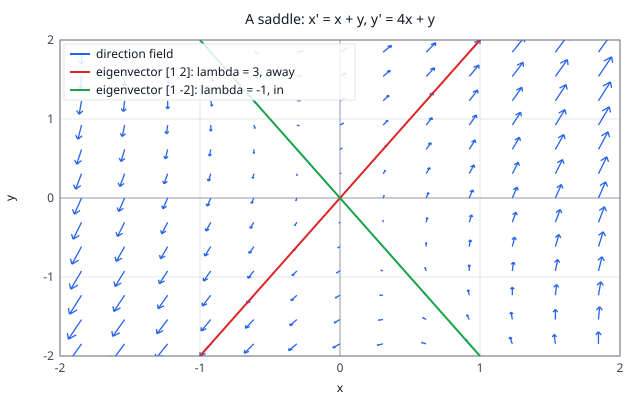

> `title`: A copy of plot p with a title or axis labels.

In [3]:
eig([1 1; 4 1])
p = show(fieldplot([x + y, 4*x + y], x, -2, 2, y, -2, 2, 13), parametric(s, 2*s, s, -1, 1), parametric(s, -2*s, s, -1, 1));
p = legend(p, "direction field", "eigenvector [1 2]: lambda = 3, away", "eigenvector [1 -2]: lambda = -1, in");
p = window(p, -2, 2, -2, 2);
labels(title(p, "A saddle: x' = x + y, y' = 4x + y"), "x", "y")

Solutions come in along $[1\ {-2}]$, turn, and leave along $[1\ 2]$. Only the solutions that start exactly on the
incoming line reach the origin.

**Try this.** Classify $x' = -x - 2y$, $y' = 2x - y$ from $T$ and $D$ before computing the eigenvalues.

## 3. Nonlinear systems: competing species

Rabbits $x$ and sheep $y$ eat the same grass (numbers in thousands):

$$x' = x(3 - x - 2y), \qquad y' = y(2 - x - y).$$

Each grows logistically alone and is slowed by the other. Equilibria are where both right-hand sides vanish:

In [4]:
f = [x*(3 - x - 2*y), y*(2 - x - y)];
solve([f(1) == 0, f(2) == 0], [x, y])

[0, 0;
 0, 2;
 1, 1;
 3, 0]

> Real solutions of the system, one per row (x, y). Found by eliminating unknowns one at a time (substitution, factoring and resultants); complex solutions are left out.

Four equilibria: nobody, only sheep $(0, 2)$, coexistence $(1, 1)$, only rabbits $(3, 0)$. Near each one, the system
behaves like its **linearization** $u' = Ju$, where $J$ is the Jacobian matrix of partial derivatives evaluated at the
point (as a tangent line approximates a curve):

In [5]:
J = jacobian(f, [x, y])
eig(subs(subs(J, x, 1), y, 1))
eig(subs(subs(J, x, 3), y, 0))
eig(subs(subs(J, x, 0), y, 2))

[3-2*x-2*y,    -2*x;
        -y, 2-x-2*y]

> Row i of the Jacobian holds the partial derivatives of the i-th function. It is the best linear approximation of the map near a point; for a change of variables its determinant is the local area (or volume) scale factor, as in dx dy = |det J| dr dθ.

[-sqrt(2)-1, sqrt(2)-1]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

[-1, -3]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

[-1, -2]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

Coexistence $(1, 1)$ is a **saddle**: unstable. Only rabbits $(3, 0)$ and only sheep $(0, 2)$ are both stable nodes
(eigenvalues $-3, -1$ and $-2, -1$). So one species always dies out, and which one depends on where you start: the
incoming line of the saddle divides the plane. Ecologists call this **competitive exclusion**.

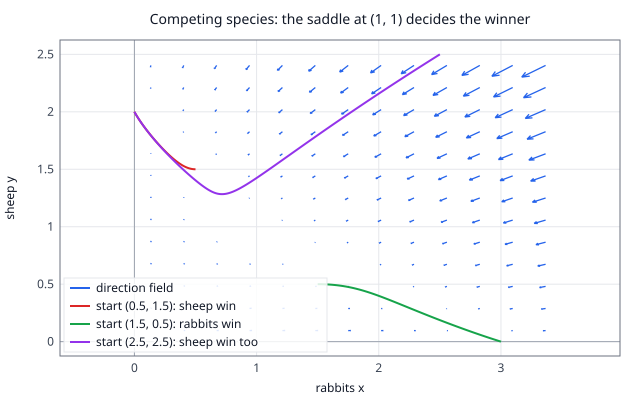

> `title`: A copy of plot p with a title or axis labels.

In [6]:
a = odeplot(f, [x y], t, [0.5 1.5], 0, 20, [x y]);
b = odeplot(f, [x y], t, [1.5 0.5], 0, 20, [x y]);
c = odeplot(f, [x y], t, [2.5 2.5], 0, 20, [x y]);
p = show(fieldplot(f, x, 0, 3.5, y, 0, 2.5, 13), a, b, c);
p = legend(p, "direction field", "start (0.5, 1.5): sheep win", "start (1.5, 0.5): rabbits win", "start (2.5, 2.5): sheep win too");
labels(title(p, "Competing species: the saddle at (1, 1) decides the winner"), "rabbits x", "sheep y")

**Try this.** Where does a start at $(2.5, 2.5)$ end, and what does that say about which side of the dividing line it
is on?

## 4. Predator and prey

Prey $x$ (hares) grow when alone; predators $y$ (lynx) die out when alone; meetings feed the predators and cost the
prey. Lotka and Volterra wrote

$$x' = x\left(1 - \frac y2\right), \qquad y' = y\left(\frac x3 - 1\right).$$

In [7]:
g = [x*(1 - y/2), y*(x/3 - 1)];
solve([g(1) == 0, g(2) == 0], [x, y])
eig(subs(subs(jacobian(g, [x, y]), x, 3), y, 2))

[0, 0;
 3, 2]

> Real solutions of the system, one per row (x, y). Found by eliminating unknowns one at a time (substitution, factoring and resultants); complex solutions are left out.

[-i, i]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

The equilibrium $(3, 2)$ has eigenvalues $\pm i$: the linearization is a **center**, and for this system the orbits
around it really are closed (the quantity $x/3 - \log x + y/2 - \log y$ stays constant along solutions). Populations
cycle forever, with the predator peak lagging a quarter period behind the prey peak:

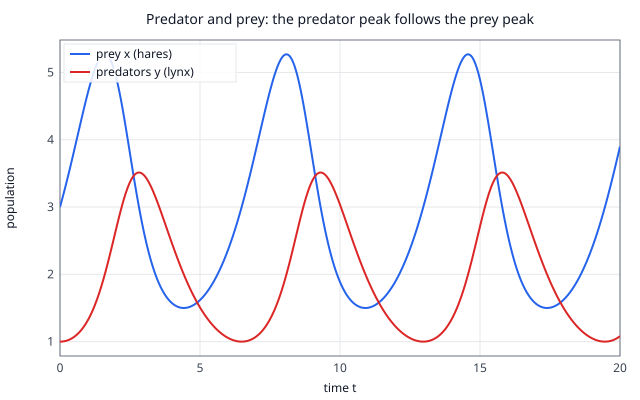

> `title`: A copy of plot p with a title or axis labels.

In [8]:
p = show(odeplot(g, [x y], t, [3 1], 0, 20, [t x]), odeplot(g, [x y], t, [3 1], 0, 20, [t y]));
p = legend(p, "prey x (hares)", "predators y (lynx)");
labels(title(p, "Predator and prey: the predator peak follows the prey peak"), "time t", "population")

**Try this.** Draw the phase portrait: `odeplot(g, [x y], t, [3 1], 0, 20, [x y])` and two more starting points,
closer to and farther from $(3, 2)$.

## 5. The pendulum

A damped pendulum at angle $\theta$ with angular velocity $v$: $\theta' = v$, $v' = -\sin\theta - v/2$. Equilibria
are $v = 0$, $\sin\theta = 0$: hanging down ($\theta = 0$) or standing up ($\theta = \pi$). The Jacobian is
$[0\ 1;\ {-\cos\theta}\ {-1/2}]$:

In [9]:
eig([0 1; -1 -1/2])
eig([0 1; 1 -1/2])

[-(1+sqrt(15)*i)/4, (-1+sqrt(15)*i)/4]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

[-(sqrt(17)+1)/4, (sqrt(17)-1)/4]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

Hanging down: complex eigenvalues with negative real part, a **stable spiral**. Standing up: a **saddle**. In the phase
plane, a push with $v = 3$ almost reaches the top and falls back; $v = 4$ carries the pendulum over the top once, and it
settles hanging down one full turn further on, at $\theta = 2\pi$.

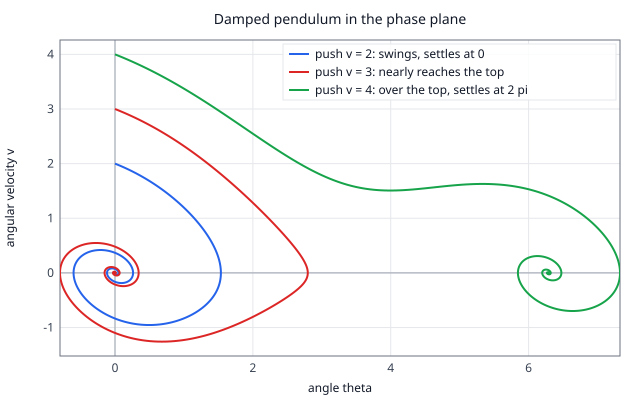

> `title`: A copy of plot p with a title or axis labels.

In [10]:
a = odeplot([v, -sin(th) - v/2], [th v], t, [0 2], 0, 30, [th v]);
b = odeplot([v, -sin(th) - v/2], [th v], t, [0 3], 0, 30, [th v]);
c = odeplot([v, -sin(th) - v/2], [th v], t, [0 4], 0, 30, [th v]);
p = show(a, b, c);
p = legend(p, "push v = 2: swings, settles at 0", "push v = 3: nearly reaches the top", "push v = 4: over the top, settles at 2 pi");
labels(title(p, "Damped pendulum in the phase plane"), "angle theta", "angular velocity v")

**Try this.** Without damping ($v' = -\sin\theta$) the hanging position is a center. Draw the phase portrait from
$v = 1, 2, 2.5$: which orbits are closed?

## Summary

* A second-order equation is a first-order system in position and velocity.
* $x' = Ax$: saddle ($D < 0$), node, spiral, center, decided by the eigenvalues, so by $T$ and $D$.
* Nonlinear systems: find equilibria, compute the Jacobian there, and classify its linearization. Saddles,
  nodes and spirals keep their type; a linear center may or may not survive.
* Phase portraits show the global story: who wins a competition, cycles of predator and prey, a pendulum going over the
  top.

Next: [series solutions](06-series-solutions.ipynb), for linear equations whose coefficients are not constant.

## Exercises

1. **System.** Solve $x' = 3x - 2y$, $y' = 2x - 2y$ with $x(0) = 1$, $y(0) = 0$, and classify the origin.
2. **Trace and determinant.** For which $k$ is the origin of $x' = y$, $y' = -kx - y$ a stable spiral? A node?
3. **Coexistence.** Change the competition to $x' = x(3 - x - y/2)$, $y' = y(2 - x/2 - y)$. Find the coexistence
   equilibrium and show that it is stable.
4. **Conserved quantity.** Check that $H = x/3 - \log x + y/2 - \log y$ is constant along solutions of the
   predator–prey system: compute $\frac{\partial H}{\partial x}x' + \frac{\partial H}{\partial y}y'$.
5. **Undamped pendulum.** Show that $E = v^2/2 - \cos\theta$ is constant for $\theta'' = -\sin\theta$. What energy
   separates swinging from going over the top?

## Hints and answers

* **Section 1, Try this.** `dsolve([y' == v, v' == -y], [y, v], t, 0, [0, 1])` gives $[\sin t, \cos t]$.
* **Section 2, Try this.** $T = -2$, $D = 5 > T^2/4 = 1$: a stable spiral (eigenvalues $-1 \pm 2i$).
* **Section 3, Try this.** It ends at $(0, 2)$: the sheep win, so it lies on the sheep's side of the incoming line of
  the saddle, even though it starts with as many rabbits as sheep.
* **Section 4, Try this.** All orbits are closed curves around $(3, 2)$, bigger for starts farther away.
* **Section 5, Try this.** $v(0) = 1$ and $2$ give closed orbits around the hanging position (for $2$, just barely);
  $2.5$ goes over the top forever, so $\theta$ keeps growing.
* **Exercise 1.** Eigenvalues 2 and $-1$: a saddle. $x = \tfrac43e^{2t} - \tfrac13e^{-t}$, $y = \tfrac23e^{2t} -
  \tfrac23e^{-t}$.
* **Exercise 2.** $T = -1$, $D = k$: spiral when $k > 1/4$, stable node when $0 < k \le 1/4$.
* **Exercise 3.** $(8/3, 2/3)$; the Jacobian there has two negative eigenvalues, so it is a stable node.
* **Exercise 4.** $(\tfrac13 - \tfrac1x)x(1 - \tfrac y2) + (\tfrac12 - \tfrac1y)y(\tfrac x3 - 1) = 0$ after
  expanding.
* **Exercise 5.** $E' = vv' + \sin\theta\,\theta' = v(-\sin\theta) + v\sin\theta = 0$. The separatrix is $E = 1$, the
  energy of standing still at the top.

## Sources

1. M. W. Hirsch, S. Smale and R. L. Devaney, *Differential Equations, Dynamical Systems, and an Introduction to Chaos*,
   3rd ed., Academic Press (2013), chapters 4, 8 and 11.
2. S. H. Strogatz, *Nonlinear Dynamics and Chaos*, 2nd ed., Westview Press (2015), chapters 5 and 6 (the rabbits and
   sheep example is from section 6.4).
3. A. J. Lotka, *Elements of Physical Biology*, Williams & Wilkins (1925); V. Volterra, "Variazioni e fluttuazioni del
   numero d'individui in specie animali conviventi", *Memorie della Accademia dei Lincei* 2 (1926) 31–113.
4. C. S. Elton and M. Nicholson, "The ten-year cycle in numbers of the lynx in Canada", *Journal of Animal Ecology* 11
   (1942) 215–244.